In [1]:
# --- Standard library ---
import json
import time
from collections import Counter
from pathlib import Path

# --- Numerical / plotting ---
import numpy as np
import matplotlib.pyplot as plt

# --- Deep learning ---
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# --- Image processing (preprocessing experiments) ---
import cv2

# --- Evaluation metrics ---
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# --- Reproducibility ---
SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791611907.167509    1124 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
OpenCV: 5.0.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# --- Paths ---
PROJECT_ROOT = Path("/home/gouth9/sign-lang-project")
DATASET_DIR = PROJECT_ROOT / "dataset" / "asl_dataset"

# --- Image / training settings ---
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

# --- Participant-independent split ---
TRAIN_PARTICIPANTS = [f"P{i}" for i in range(1, 9)]   # P1-P8
VAL_PARTICIPANTS = ["P9"]
TEST_PARTICIPANTS = ["P10"]

# --- Classes: one folder per class ---
classes = sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir())
class_to_index = {name: i for i, name in enumerate(classes)}

print("Dataset dir exists:", DATASET_DIR.exists())
print("Number of classes:", len(classes))
print("Classes:", classes)


Dataset dir exists: True
Number of classes: 36
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [4]:
def collect_split(participants):
    """Return (paths, labels) for every image whose participant is in `participants`."""
    paths, labels = [], []
    for class_name in classes:
        for img_path in sorted((DATASET_DIR / class_name).glob("*.jpg")):
            participant = img_path.stem.split("_")[0]   # "P5_A_433" -> "P5"
            if participant in participants:
                paths.append(str(img_path))
                labels.append(class_to_index[class_name])
    return paths, labels

train_paths, train_labels = collect_split(TRAIN_PARTICIPANTS)
val_paths,   val_labels   = collect_split(VAL_PARTICIPANTS)
test_paths,  test_labels  = collect_split(TEST_PARTICIPANTS)

print("Train:", len(train_paths))
print("Val:  ", len(val_paths))
print("Test: ", len(test_paths))
print("Overlap train/val:", set(train_paths) & set(val_paths) != set())
print("Overlap train/test:", set(train_paths) & set(test_paths) != set())
print("Overlap val/test:", set(val_paths) & set(test_paths) != set())

Train: 28800
Val:   3600
Test:  3600
Overlap train/val: False
Overlap train/test: False
Overlap val/test: False


In [5]:
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0
    return image, label


def make_dataset(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_dataset = make_dataset(train_paths, train_labels, training=True)
val_dataset   = make_dataset(val_paths,   val_labels,   training=False)
test_dataset  = make_dataset(test_paths,  test_labels,  training=False)

images, labels = next(iter(train_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range: %.3f to %.3f" % (images.numpy().min(), images.numpy().max()))
print("Labels in first batch:", labels.numpy())

I0000 00:00:1791611940.005415    1124 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2242 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 0.000 to 1.000
Labels in first batch: [26 30 22  3 32 18 23  5  6  9 27 24 18 19 34  6  7 24 10  2  7 21  7 10
  4 20  2 35 25 24  6 13]


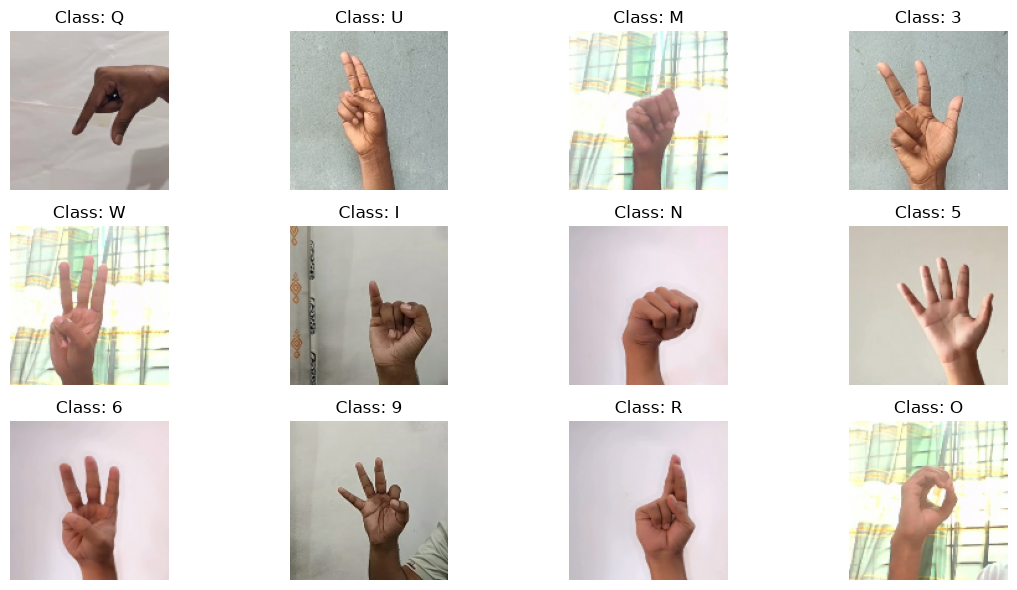

In [12]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(f"Class: {classes[labels[i].numpy()]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [8]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, (3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    return x

inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
x = conv_block(inputs, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = conv_block(x, 256)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)

baseline_model = keras.Model(inputs, outputs, name="baseline_cnn")
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,956 (1.62 MB)

 Trainable params: 425,956 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

loss, acc = baseline_model.evaluate(val_dataset, steps=20)
print(f"Untrained model -> loss: {loss:.3f}, accuracy: {acc:.3f}")
print(f"Expected for random guessing -> loss: {np.log(len(classes)):.3f}, accuracy: {1/len(classes):.3f}")

I0000 00:00:1791524562.525123    2719 service.cc:153] XLA service 0x73bf3802ef90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791524562.525149    2719 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce GTX 1650 Ti, Compute Capability 7.5 (Driver: 12.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791524562.612980    2719 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791524562.692253    2719 cuda_dnn.cc:461] Loaded cuDNN version 92700


 9/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0000e+00 - loss: 3.5822

I0000 00:00:1791524565.352386    2719 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.0000e+00 - loss: 3.5792
Untrained model -> loss: 3.579, accuracy: 0.000
Expected for random guessing -> loss: 3.584, accuracy: 0.028


In [15]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

EPOCHS = 30

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "baseline_cnn.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

start = time.time()
history = baseline_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
)
print(f"Training time: {(time.time() - start) / 60:.1f} min")

Epoch 1/30


/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791524568.024179    2719 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3004__.50
E0000 00:00:1791524571.607462    2719 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


900/900 ━━━━━━━━━━━━━━━━━━━━ 47s 41ms/step - accuracy: 0.1391 - loss: 2.8793 - val_accuracy: 0.3803 - val_loss: 1.5534
Epoch 2/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 38s 42ms/step - accuracy: 0.6434 - loss: 0.9621 - val_accuracy: 0.5728 - val_loss: 1.1296
Epoch 3/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 39s 43ms/step - accuracy: 0.8602 - loss: 0.3718 - val_accuracy: 0.6150 - val_loss: 1.2468
Epoch 4/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 44s 49ms/step - accuracy: 0.9303 - loss: 0.1977 - val_accuracy: 0.6944 - val_loss: 1.1752
Epoch 5/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 72s 80ms/step - accuracy: 0.9559 - loss: 0.1275 - val_accuracy: 0.7167 - val_loss: 0.9937
Epoch 6/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 72s 80ms/step - accuracy: 0.9669 - loss: 0.0960 - val_accuracy: 0.7461 - val_loss: 0.9955
Epoch 7/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 73s 81ms/step - accuracy: 0.9739 - loss: 0.0759 - val_accuracy: 0.6864 - val_loss: 1.3761
Epoch 8/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 75s 84ms/step - accuracy: 0.9769 - loss: 0.0673 - val_accurac

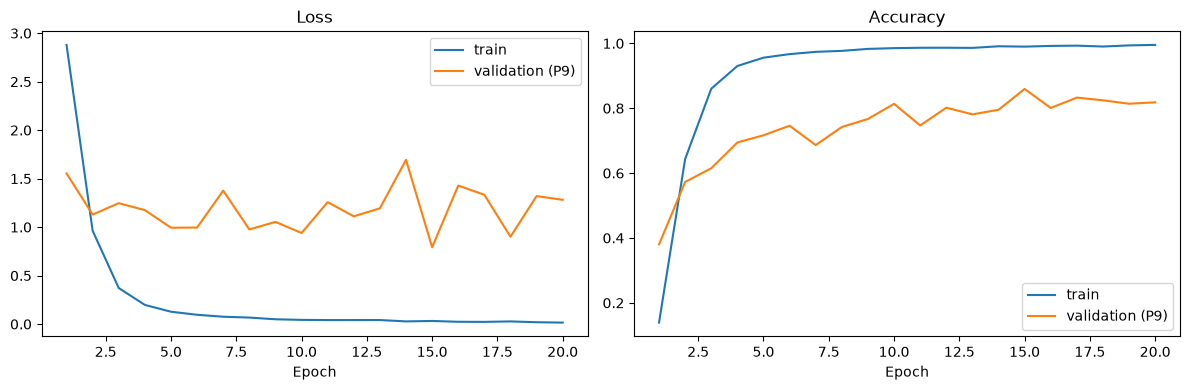

In [16]:
hist = history.history
epochs_ran = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, hist["loss"], label="train")
axes[0].plot(epochs_ran, hist["val_loss"], label="validation (P9)")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_ran, hist["accuracy"], label="train")
axes[1].plot(epochs_ran, hist["val_accuracy"], label="validation (P9)")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step
Validation accuracy: 0.8594444444444445


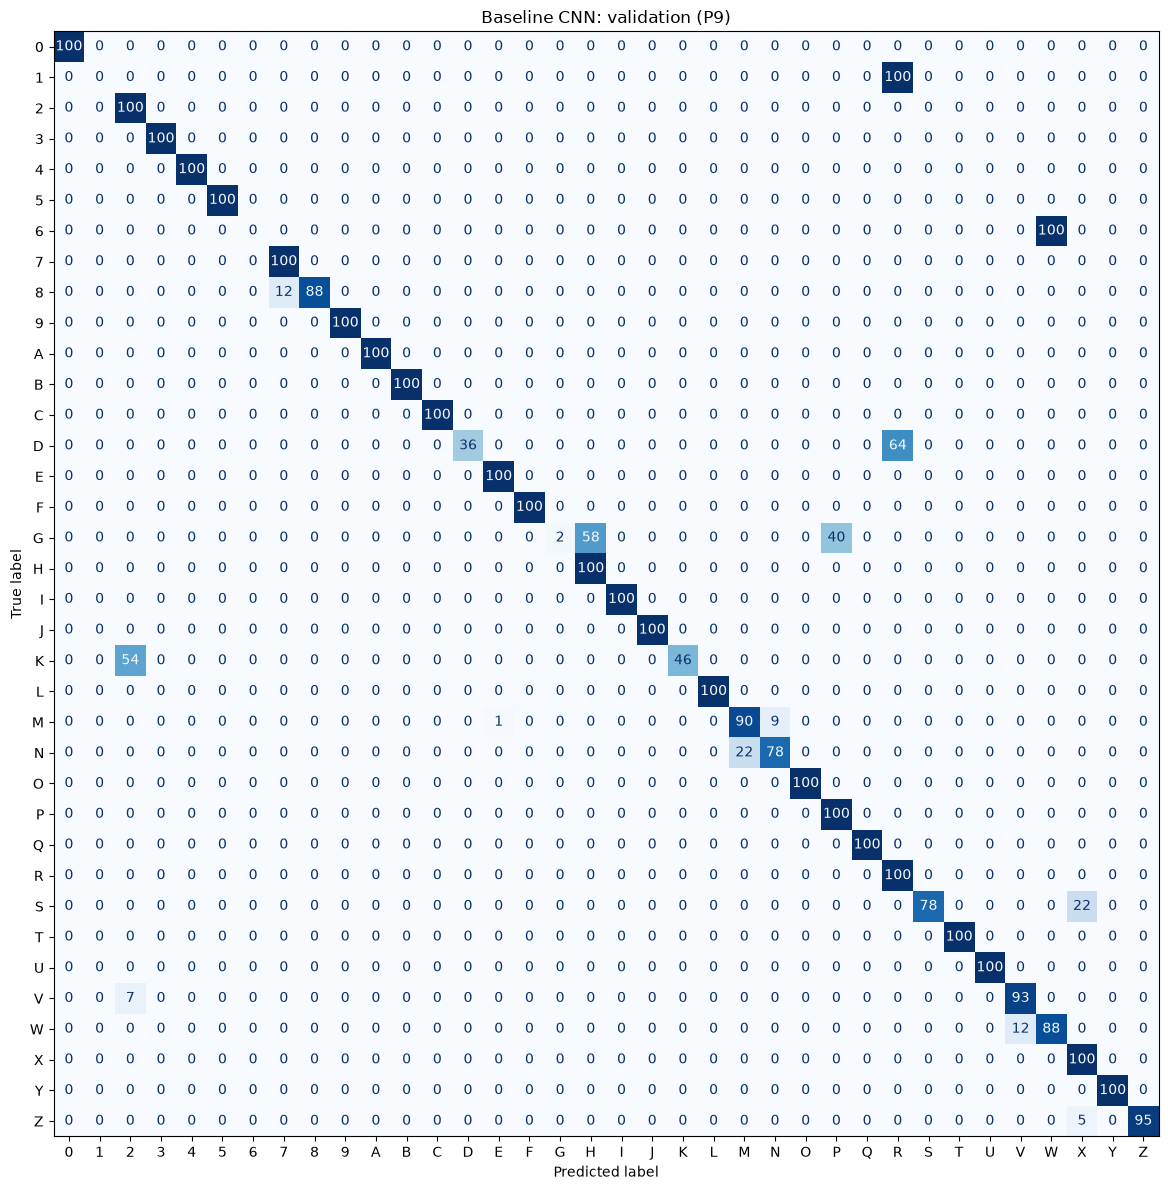

In [17]:
val_probs = baseline_model.predict(val_dataset)
val_pred = np.argmax(val_probs, axis=1)
val_true = np.array(val_labels)

print("Validation accuracy:", (val_pred == val_true).mean())

cm = confusion_matrix(val_true, val_pred)

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Baseline CNN: validation (P9)")
plt.tight_layout()
plt.show()


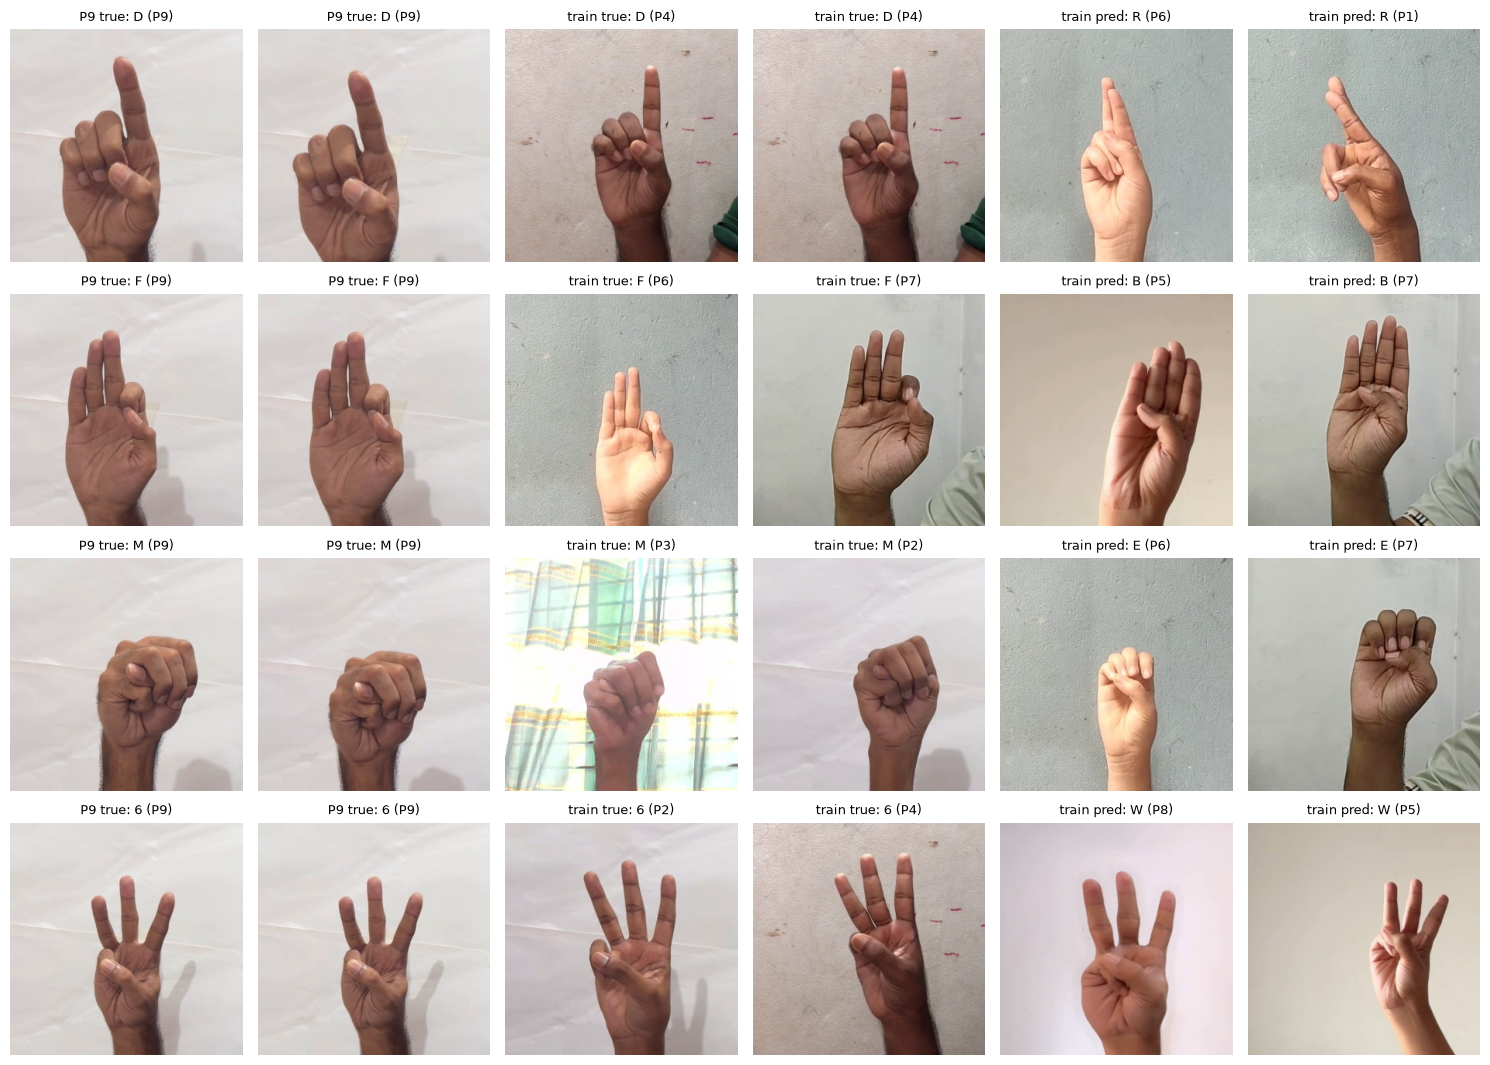

In [18]:
rng = np.random.default_rng(SEED)

def pick(paths, labels, class_idx, n):
    pool = [p for p, l in zip(paths, labels) if l == class_idx]
    return list(rng.choice(pool, size=n, replace=False))

pairs = [("D", "R"), ("F", "B"), ("M", "E"), ("6", "W")]
col_titles = ["P9 true", "P9 true", "train true", "train true", "train pred", "train pred"]

fig, axes = plt.subplots(len(pairs), 6, figsize=(15, 2.7 * len(pairs)))
for r, (true_name, pred_name) in enumerate(pairs):
    t, p = class_to_index[true_name], class_to_index[pred_name]
    row = (
        pick(val_paths, val_labels, t, 2)
        + pick(train_paths, train_labels, t, 2)
        + pick(train_paths, train_labels, p, 2)
    )
    names = [true_name] * 4 + [pred_name] * 2
    for c, (img_path, name) in enumerate(zip(row, names)):
        participant = Path(img_path).stem.split("_")[0]
        axes[r, c].imshow(plt.imread(img_path))
        axes[r, c].set_title(f"{col_titles[c]}: {name} ({participant})", fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

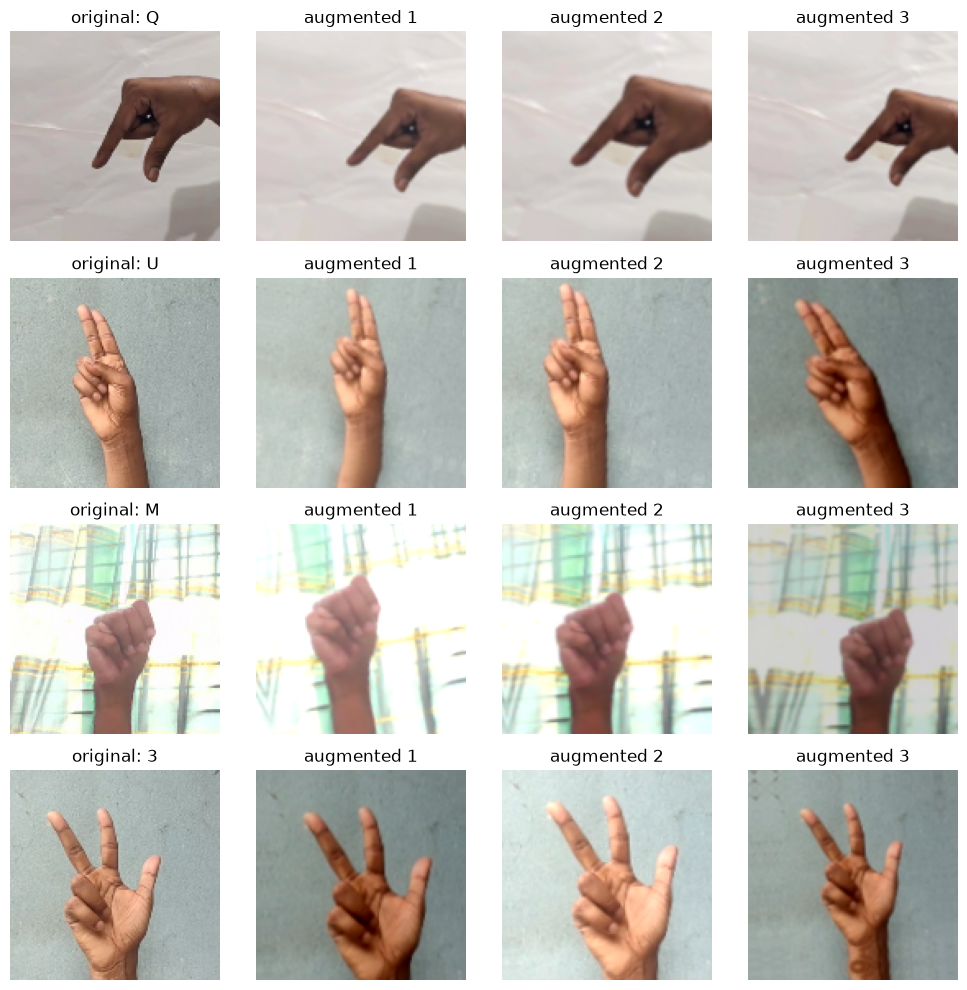

In [19]:
baseline_history = history.history   # keep baseline results for comparison

data_augmentation = keras.Sequential([
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.15),
    layers.RandomRotation(0.04),
    layers.RandomBrightness(0.2, value_range=(0, 1)),
    layers.RandomContrast(0.2),
], name="augmentation")

# Preview: 4 images from the earlier batch, each shown original + 3 random augmentations
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r in range(4):
    img = images[r:r+1]
    axes[r, 0].imshow(img[0].numpy())
    axes[r, 0].set_title(f"original: {classes[labels[r].numpy()]}")
    for c in range(1, 4):
        out = data_augmentation(img, training=True)[0]
        axes[r, c].imshow(tf.clip_by_value(out, 0, 1).numpy())
        axes[r, c].set_title(f"augmented {c}")
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout()
plt.show()

In [20]:
def build_cnn(name, augmentation=None):
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
    x = inputs
    if augmentation is not None:
        x = augmentation(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(classes), activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)


keras.utils.set_random_seed(SEED)   # same starting point as the baseline
aug_model = build_cnn("augmented_cnn", augmentation=data_augmentation)

aug_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

aug_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "augmented_cnn.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

start = time.time()
aug_history = aug_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=aug_callbacks,
)
print(f"Training time: {(time.time() - start) / 60:.1f} min")

Epoch 1/30


/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


900/900 ━━━━━━━━━━━━━━━━━━━━ 75s 74ms/step - accuracy: 0.0291 - loss: 3.5759 - val_accuracy: 0.0278 - val_loss: 3.5839
Epoch 2/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 68s 76ms/step - accuracy: 0.1910 - loss: 2.6862 - val_accuracy: 0.5825 - val_loss: 1.0243
Epoch 3/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 70s 77ms/step - accuracy: 0.6430 - loss: 0.9814 - val_accuracy: 0.8581 - val_loss: 0.3791
Epoch 4/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 68s 75ms/step - accuracy: 0.8097 - loss: 0.5046 - val_accuracy: 0.8572 - val_loss: 0.3354
Epoch 5/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 68s 76ms/step - accuracy: 0.8741 - loss: 0.3390 - val_accuracy: 0.9289 - val_loss: 0.1941
Epoch 6/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 69s 76ms/step - accuracy: 0.9133 - loss: 0.2298 - val_accuracy: 0.8989 - val_loss: 0.3224
Epoch 7/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 68s 75ms/step - accuracy: 0.9354 - loss: 0.1791 - val_accuracy: 0.9217 - val_loss: 0.2458
Epoch 8/30
900/900 ━━━━━━━━━━━━━━━━━━━━ 68s 75ms/step - accuracy: 0.9567 - loss: 0.1272 - val_accurac

113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step
Baseline  val accuracy: 0.8594444444444445
Augmented val accuracy: 0.9288888888888889

Class  baseline  augmented   (shown if either is below 90%)
    1        0%       100%
    6        0%         0%
    8       88%        72%
    D       36%        93%
    G        2%       100%
    K       46%       100%
    M       90%         1%
    N       78%        88%
    S       78%       100%
    W       88%       100%


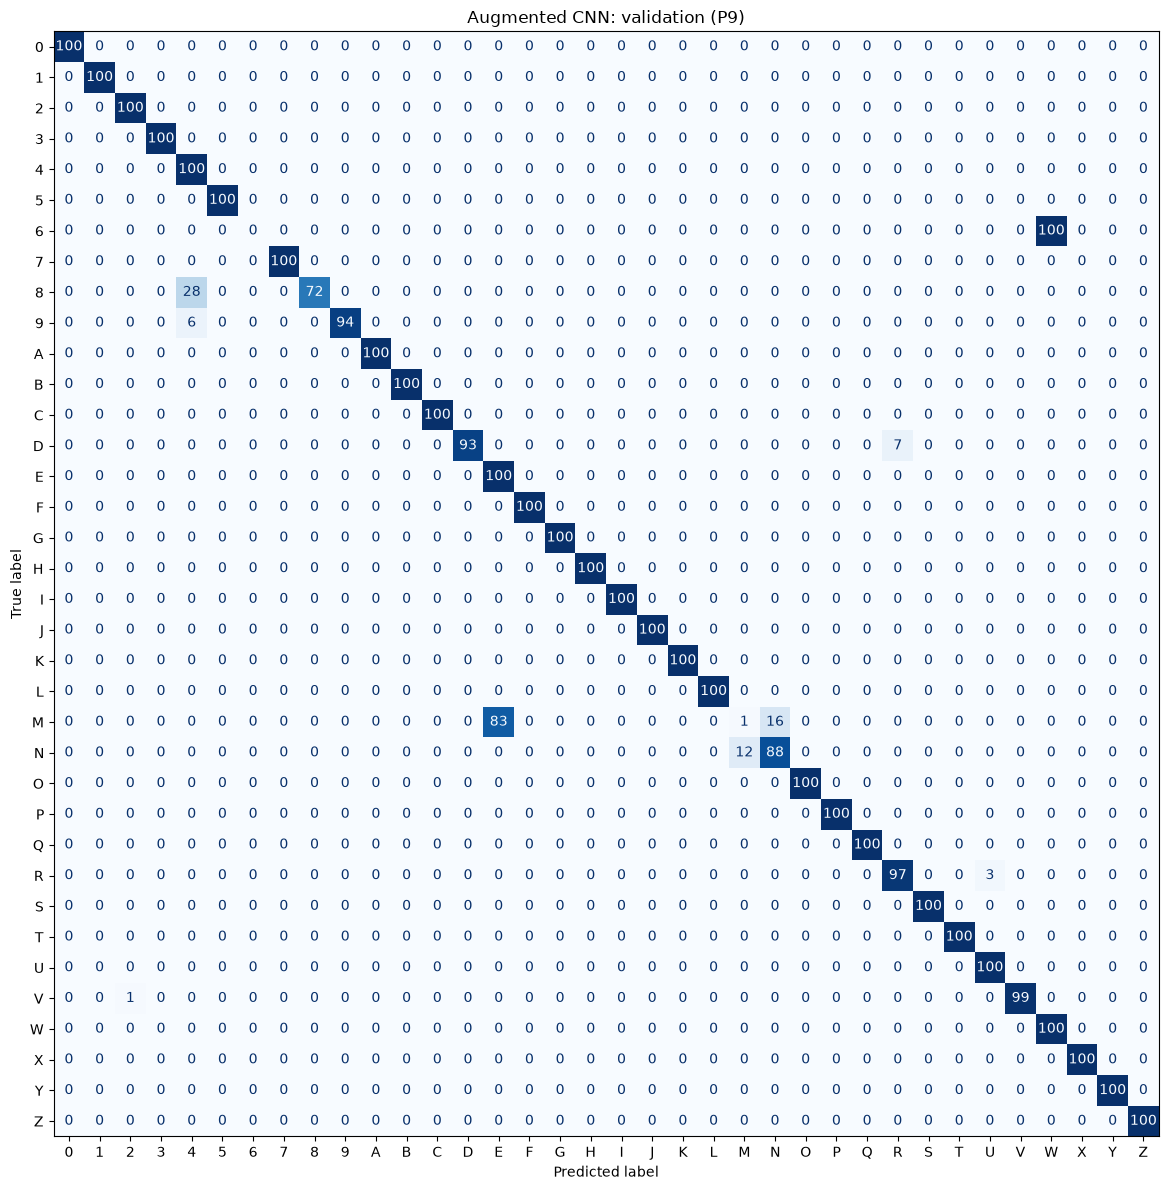

In [21]:
val_true = np.array(val_labels)   # lost in the restart; same order as val_dataset

aug_pred = np.argmax(aug_model.predict(val_dataset), axis=1)

baseline_loaded = keras.models.load_model(MODELS_DIR / "baseline_cnn.keras")
base_pred = np.argmax(baseline_loaded.predict(val_dataset), axis=1)

print("Baseline  val accuracy:", (base_pred == val_true).mean())
print("Augmented val accuracy:", (aug_pred == val_true).mean())

print("\nClass  baseline  augmented   (shown if either is below 90%)")
for i, name in enumerate(classes):
    b = (base_pred[val_true == i] == i).mean()
    a = (aug_pred[val_true == i] == i).mean()
    if a < 0.9 or b < 0.9:
        print(f"{name:>5}  {b:8.0%}  {a:9.0%}")

cm_aug = confusion_matrix(val_true, aug_pred)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm_aug, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Augmented CNN: validation (P9)")
plt.tight_layout()
plt.show()

In [9]:
EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"
EXPERIMENTS_DIR.mkdir(exist_ok=True)

def save_run(name, seed, model, hist, notes=""):
    """Save model + settings + per-epoch history under a unique name. Refuses to overwrite."""
    run_id = f"{name}_seed{seed}"
    model_path = MODELS_DIR / f"{run_id}.keras"
    json_path = EXPERIMENTS_DIR / f"{run_id}.json"
    if model_path.exists() or json_path.exists():
        raise FileExistsError(f"{run_id} already saved; pick a new name or seed.")

    best_epoch = int(np.argmin(hist["val_loss"])) + 1
    record = {
        "run_id": run_id,
        "seed": seed,
        "image_size": list(IMAGE_SIZE),
        "batch_size": BATCH_SIZE,
        "train_participants": TRAIN_PARTICIPANTS,
        "val_participants": VAL_PARTICIPANTS,
        "best_epoch": best_epoch,
        "best_val_loss": float(min(hist["val_loss"])),
        "val_accuracy_at_best_epoch": float(hist["val_accuracy"][best_epoch - 1]),
        "history": {k: [float(v) for v in vals] for k, vals in hist.items()},
        "notes": notes,
    }
    model.save(model_path)
    json_path.write_text(json.dumps(record, indent=2))
    print("Saved:", model_path.name, "and", json_path.name)

In [23]:
save_run("baseline", 42, baseline_model, history.history,
         notes="second baseline run; first run (70.3% val) was overwritten by Run All")
save_run("augmented", 42, aug_model, aug_history.history,
         notes="aug: translate .1, zoom .15, rotate .04, brightness .2, contrast .2")

Saved: baseline_seed42.keras and baseline_seed42.json
Saved: augmented_seed42.keras and augmented_seed42.json


In [24]:
def make_dataset(paths, labels, training, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

def make_augmentation():
    return keras.Sequential([
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomZoom(0.15),
        layers.RandomRotation(0.04),
        layers.RandomBrightness(0.2, value_range=(0, 1)),
        layers.RandomContrast(0.2),
    ], name="augmentation")

results = []
for seed in [43, 44]:
    for name, use_aug in [("baseline", False), ("augmented", True)]:
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)

        ds_train = make_dataset(train_paths, train_labels, training=True, seed=seed)
        model = build_cnn(f"{name}_cnn", augmentation=make_augmentation() if use_aug else None)
        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss=keras.losses.SparseCategoricalCrossentropy(),
            metrics=["accuracy"],
        )
        h = model.fit(
            ds_train,
            validation_data=val_dataset,
            epochs=EPOCHS,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=5, restore_best_weights=True)],
            verbose=2,
        )
        save_run(name, seed, model, h.history,
                 notes="seed repeat; shuffle seed also varied")
        best = int(np.argmin(h.history["val_loss"]))
        results.append((name, seed, h.history["val_accuracy"][best]))

print("\nRun summary (val accuracy at best epoch):")
for name, seed, acc in results:
    print(f"{name:>10}  seed {seed}: {acc:.3f}")

Epoch 1/30


/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791527110.508635    2715 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_140735__.50


900/900 - 39s - 44ms/step - accuracy: 0.1003 - loss: 3.1721 - val_accuracy: 0.3847 - val_loss: 1.8085
Epoch 2/30
900/900 - 36s - 40ms/step - accuracy: 0.7115 - loss: 0.8074 - val_accuracy: 0.6292 - val_loss: 1.0627
Epoch 3/30
900/900 - 36s - 40ms/step - accuracy: 0.9291 - loss: 0.1992 - val_accuracy: 0.6811 - val_loss: 1.3882
Epoch 4/30
900/900 - 42s - 47ms/step - accuracy: 0.9647 - loss: 0.1032 - val_accuracy: 0.7653 - val_loss: 1.0072
Epoch 5/30
900/900 - 46s - 51ms/step - accuracy: 0.9749 - loss: 0.0737 - val_accuracy: 0.8231 - val_loss: 1.1783
Epoch 6/30
900/900 - 71s - 79ms/step - accuracy: 0.9775 - loss: 0.0664 - val_accuracy: 0.8358 - val_loss: 1.0679
Epoch 7/30
900/900 - 69s - 77ms/step - accuracy: 0.9835 - loss: 0.0502 - val_accuracy: 0.6797 - val_loss: 2.0198
Epoch 8/30
900/900 - 71s - 79ms/step - accuracy: 0.9849 - loss: 0.0459 - val_accuracy: 0.7825 - val_loss: 1.5955
Epoch 9/30
900/900 - 71s - 79ms/step - accuracy: 0.9882 - loss: 0.0344 - val_accuracy: 0.8025 - val_loss: 1

I0000 00:00:1791528687.732885    2716 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_249340__.50


900/900 - 79s - 87ms/step - accuracy: 0.1267 - loss: 2.9881 - val_accuracy: 0.3592 - val_loss: 1.7361
Epoch 2/30
900/900 - 74s - 82ms/step - accuracy: 0.6821 - loss: 0.9041 - val_accuracy: 0.6303 - val_loss: 1.0566
Epoch 3/30
900/900 - 75s - 83ms/step - accuracy: 0.9102 - loss: 0.2596 - val_accuracy: 0.6186 - val_loss: 1.2347
Epoch 4/30
900/900 - 73s - 81ms/step - accuracy: 0.9558 - loss: 0.1314 - val_accuracy: 0.6703 - val_loss: 1.3482
Epoch 5/30
900/900 - 73s - 81ms/step - accuracy: 0.9694 - loss: 0.0931 - val_accuracy: 0.6186 - val_loss: 1.2819
Epoch 6/30
900/900 - 74s - 82ms/step - accuracy: 0.9767 - loss: 0.0699 - val_accuracy: 0.6267 - val_loss: 1.2138
Epoch 7/30
900/900 - 72s - 80ms/step - accuracy: 0.9826 - loss: 0.0519 - val_accuracy: 0.7314 - val_loss: 1.1434
Saved: baseline_seed44.keras and baseline_seed44.json
Epoch 1/30
900/900 - 68s - 75ms/step - accuracy: 0.0586 - loss: 3.4096 - val_accuracy: 0.3039 - val_loss: 2.2633
Epoch 2/30
900/900 - 67s - 74ms/step - accuracy: 0.48

In [25]:
for name in ["baseline", "augmented"]:
    accs = []
    for seed in [42, 43, 44]:
        r = json.loads((EXPERIMENTS_DIR / f"{name}_seed{seed}.json").read_text())
        accs.append(r["val_accuracy_at_best_epoch"])
        print(f"{name:>10} seed {seed}: best epoch {r['best_epoch']:>2}, "
              f"val_loss {r['best_val_loss']:.3f}, val_acc {r['val_accuracy_at_best_epoch']:.3f}")
    print(f"{name:>10} mean {np.mean(accs):.3f}  min {min(accs):.3f}  max {max(accs):.3f}\n")

  baseline seed 42: best epoch 15, val_loss 0.792, val_acc 0.859
  baseline seed 43: best epoch  4, val_loss 1.007, val_acc 0.765
  baseline seed 44: best epoch  2, val_loss 1.057, val_acc 0.630
  baseline mean 0.752  min 0.630  max 0.859

 augmented seed 42: best epoch  5, val_loss 0.194, val_acc 0.929
 augmented seed 43: best epoch 11, val_loss 0.189, val_acc 0.932
 augmented seed 44: best epoch  4, val_loss 0.244, val_acc 0.908
 augmented mean 0.923  min 0.908  max 0.932



113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Test accuracy (P10): 0.8325

              precision    recall  f1-score   support

           0      1.000     1.000     1.000       100
           1      0.658     1.000     0.794       100
           2      0.500     1.000     0.667       100
           3      1.000     1.000     1.000       100
           4      1.000     0.570     0.726       100
           5      1.000     1.000     1.000       100
           6      0.595     1.000     0.746       100
           7      1.000     1.000     1.000       100
           8      0.500     1.000     0.667       100
           9      0.000     0.000     0.000       100
           A      1.000     1.000     1.000       100
           B      1.000     1.000     1.000       100
           C      1.000     1.000     1.000       100
           D      1.000     0.480     0.649       100
           E      1.000     0.060     0.113       100
           F      1.000     1.000     1.000       100
          

/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

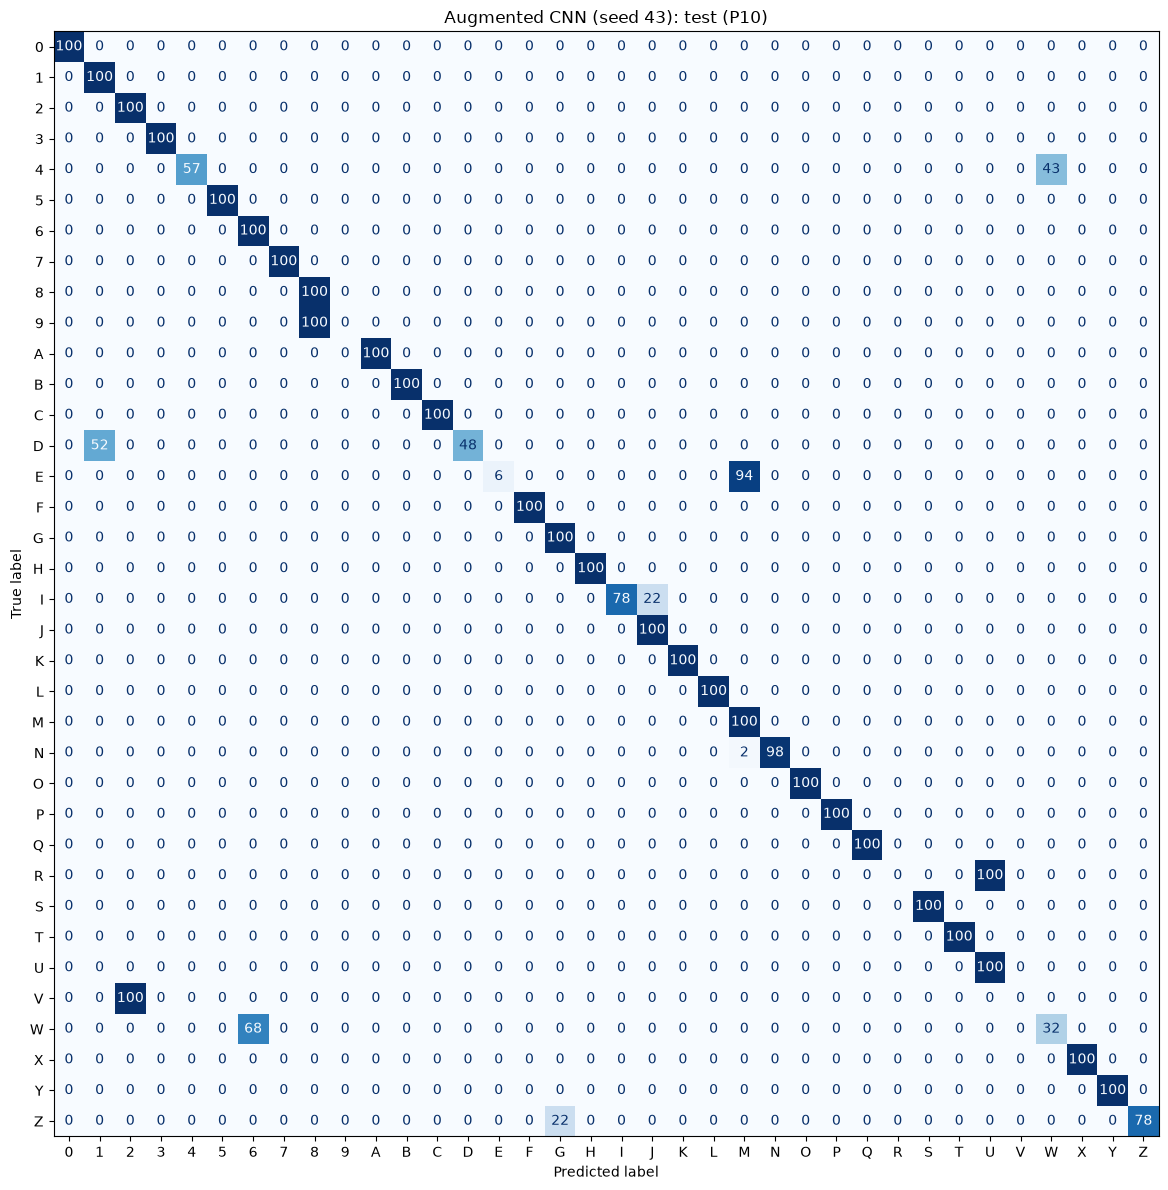

In [26]:
final_model = keras.models.load_model(MODELS_DIR / "augmented_seed43.keras")

test_probs = final_model.predict(test_dataset)
test_pred = np.argmax(test_probs, axis=1)
test_true = np.array(test_labels)

print("Test accuracy (P10):", (test_pred == test_true).mean())
print()
print(classification_report(test_true, test_pred, target_names=classes, digits=3))

cm_test = confusion_matrix(test_true, test_pred)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm_test, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Augmented CNN (seed 43): test (P10)")
plt.tight_layout()
plt.show()

In [27]:
IMAGE_SIZE = (192, 192)   # global used by load_and_preprocess_image and build_cnn

val_dataset_192 = make_dataset(val_paths, val_labels, training=False)

SEEDS = [42]              # run seed 42 first; later change to [43, 44]
results_192 = []
for seed in SEEDS:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    ds_train = make_dataset(train_paths, train_labels, training=True, seed=seed)
    model = build_cnn("aug192_cnn", augmentation=make_augmentation())
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    h = model.fit(
        ds_train,
        validation_data=val_dataset_192,
        epochs=EPOCHS,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True)],
        verbose=2,
    )
    save_run("aug192", seed, model, h.history, notes="192x192 + augmentation")
    best = int(np.argmin(h.history["val_loss"]))
    results_192.append((seed, h.history["val_accuracy"][best]))

for seed, acc in results_192:
    print(f"aug192 seed {seed}: {acc:.3f}")

IMAGE_SIZE = (128, 128)   # restore, so later cells and the webcam stay consistent

Epoch 1/30


/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


900/900 - 80s - 88ms/step - accuracy: 0.0962 - loss: 3.1645 - val_accuracy: 0.4058 - val_loss: 1.8665
Epoch 2/30
900/900 - 78s - 87ms/step - accuracy: 0.5012 - loss: 1.4460 - val_accuracy: 0.7236 - val_loss: 0.5932
Epoch 3/30
900/900 - 116s - 129ms/step - accuracy: 0.7606 - loss: 0.6446 - val_accuracy: 0.8219 - val_loss: 0.4209
Epoch 4/30
900/900 - 141s - 156ms/step - accuracy: 0.8603 - loss: 0.3868 - val_accuracy: 0.8067 - val_loss: 0.4082
Epoch 5/30
900/900 - 141s - 157ms/step - accuracy: 0.9008 - loss: 0.2691 - val_accuracy: 0.8556 - val_loss: 0.3612
Epoch 6/30
900/900 - 141s - 157ms/step - accuracy: 0.9302 - loss: 0.1963 - val_accuracy: 0.8933 - val_loss: 0.3543
Epoch 7/30
900/900 - 142s - 158ms/step - accuracy: 0.9422 - loss: 0.1587 - val_accuracy: 0.8928 - val_loss: 0.3041
Epoch 8/30
900/900 - 143s - 159ms/step - accuracy: 0.9521 - loss: 0.1358 - val_accuracy: 0.8097 - val_loss: 0.6657
Epoch 9/30
900/900 - 144s - 160ms/step - accuracy: 0.9604 - loss: 0.1106 - val_accuracy: 0.9178

In [28]:
IMAGE_SIZE = (192, 192)
m192 = keras.models.load_model(MODELS_DIR / "aug192_seed42.keras")
p192 = np.argmax(m192.predict(val_dataset_192), axis=1)
IMAGE_SIZE = (128, 128)

m128 = keras.models.load_model(MODELS_DIR / "augmented_seed42.keras")
p128 = np.argmax(m128.predict(val_dataset), axis=1)

print("Class  128px  192px   (shown if either is below 90%)")
for i, name in enumerate(classes):
    a = (p128[val_true == i] == i).mean()
    b = (p192[val_true == i] == i).mean()
    if a < 0.9 or b < 0.9:
        print(f"{name:>5}  {a:5.0%}  {b:5.0%}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Class  128px  192px   (shown if either is below 90%)
    6     0%     0%
    8    72%    83%
    D    93%    79%
    M     1%     0%
    N    88%     0%
    S   100%    71%
    T   100%    81%


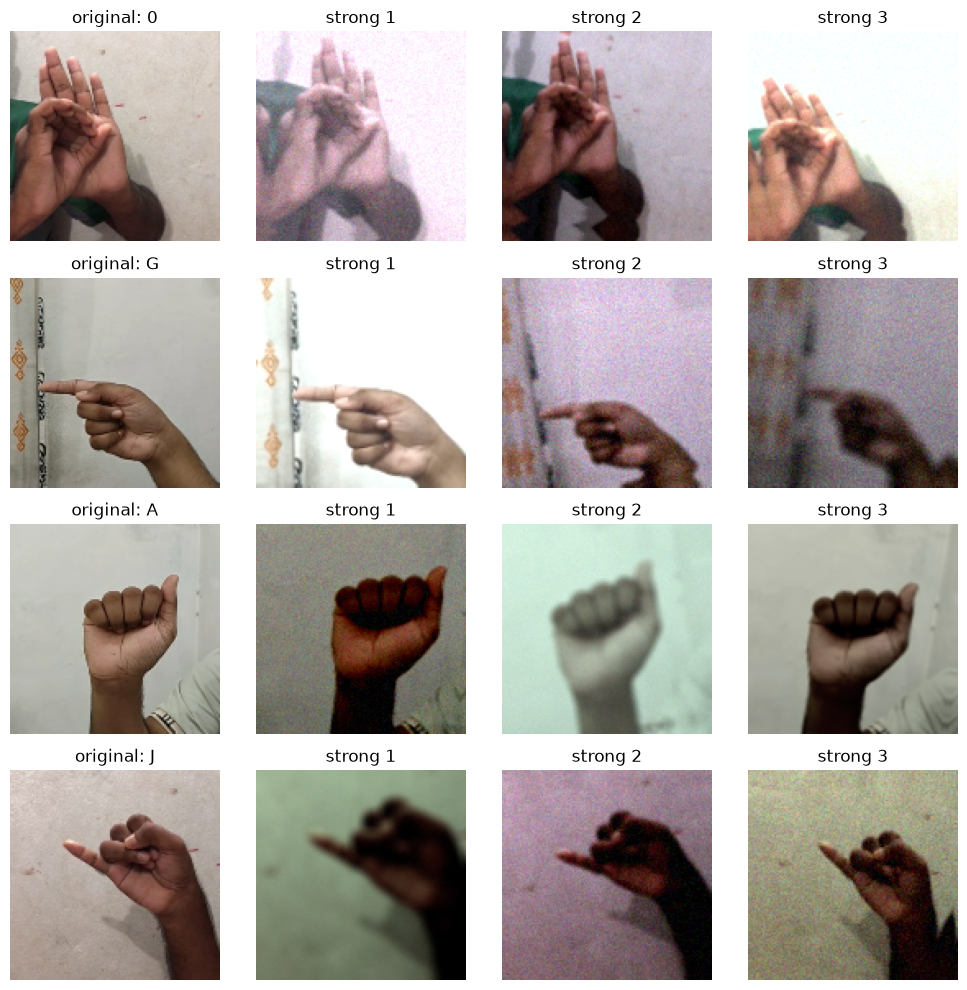

In [31]:
class WebcamStyleAugment(layers.Layer):
    """Blur, noise, saturation and per-channel color gain. Active only in training."""

    def call(self, x, training=None):
        if not training:
            return x
        b = tf.shape(x)[0]

        gray = tf.reduce_mean(x, axis=-1, keepdims=True)
        sat = tf.random.uniform([b, 1, 1, 1], 0.3, 1.3)
        x = gray + (x - gray) * sat

        gain = tf.random.uniform([b, 1, 1, 3], 0.9, 1.1)
        x = x * gain

        def blur():
            idx = tf.random.uniform([], 0, 3, dtype=tf.int32)
            return tf.switch_case(idx, [
                lambda: tf.nn.avg_pool2d(x, ksize=3, strides=1, padding="SAME"),
                lambda: tf.nn.avg_pool2d(x, ksize=5, strides=1, padding="SAME"),
                lambda: tf.nn.avg_pool2d(x, ksize=7, strides=1, padding="SAME"),
            ])

        x = tf.cond(tf.random.uniform([]) < 0.5, blur, lambda: x)

        sigma = tf.random.uniform([b, 1, 1, 1], 0.0, 0.05)
        x = x + tf.random.normal(tf.shape(x)) * sigma

        return tf.clip_by_value(x, 0.0, 1.0)


def make_strong_augmentation():
    return keras.Sequential([
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomZoom(0.15),
        layers.RandomRotation(0.04),
        layers.RandomBrightness(0.3, value_range=(0, 1)),
        layers.RandomContrast(0.35),
        WebcamStyleAugment(),
    ], name="strong_augmentation")


images, labels = next(iter(train_dataset))   # fresh batch of 32 training images

aug_preview = make_strong_augmentation()
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r in range(4):
    img = images[r:r+1]
    axes[r, 0].imshow(img[0].numpy())
    axes[r, 0].set_title(f"original: {classes[labels[r].numpy()]}")
    for c in range(1, 4):
        out = aug_preview(img, training=True)[0]
        axes[r, c].imshow(tf.clip_by_value(out, 0, 1).numpy())
        axes[r, c].set_title(f"strong {c}")
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout()
plt.show()

In [32]:
results_strong = []
for seed in [42, 43, 44]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    ds_train = make_dataset(train_paths, train_labels, training=True, seed=seed)
    model = build_cnn("augstrong_cnn", augmentation=make_strong_augmentation())
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    h = model.fit(
        ds_train,
        validation_data=val_dataset,
        epochs=EPOCHS,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True)],
        verbose=2,
    )
    save_run("augstrong", seed, model, h.history,
             notes="strong aug: blur, noise, saturation, color gain")
    best = int(np.argmin(h.history["val_loss"]))
    results_strong.append((seed, h.history["val_accuracy"][best]))

for seed, acc in results_strong:
    print(f"augstrong seed {seed}: {acc:.3f}")

Epoch 1/30
900/900 - 49s - 54ms/step - accuracy: 0.0342 - loss: 3.5364 - val_accuracy: 0.0278 - val_loss: 3.0435
Epoch 2/30
900/900 - 50s - 55ms/step - accuracy: 0.1961 - loss: 2.6485 - val_accuracy: 0.4267 - val_loss: 1.3276
Epoch 3/30
900/900 - 51s - 57ms/step - accuracy: 0.5692 - loss: 1.2495 - val_accuracy: 0.7142 - val_loss: 0.6960
Epoch 4/30
900/900 - 52s - 58ms/step - accuracy: 0.7521 - loss: 0.6861 - val_accuracy: 0.7531 - val_loss: 0.9314
Epoch 5/30
900/900 - 53s - 58ms/step - accuracy: 0.8290 - loss: 0.4764 - val_accuracy: 0.8519 - val_loss: 0.5305
Epoch 6/30
900/900 - 53s - 59ms/step - accuracy: 0.8769 - loss: 0.3346 - val_accuracy: 0.8850 - val_loss: 0.2688
Epoch 7/30
900/900 - 53s - 59ms/step - accuracy: 0.9073 - loss: 0.2627 - val_accuracy: 0.8853 - val_loss: 0.3333
Epoch 8/30
900/900 - 54s - 60ms/step - accuracy: 0.9239 - loss: 0.2140 - val_accuracy: 0.8467 - val_loss: 0.4423
Epoch 9/30
900/900 - 54s - 60ms/step - accuracy: 0.9380 - loss: 0.1790 - val_accuracy: 0.8708 - 

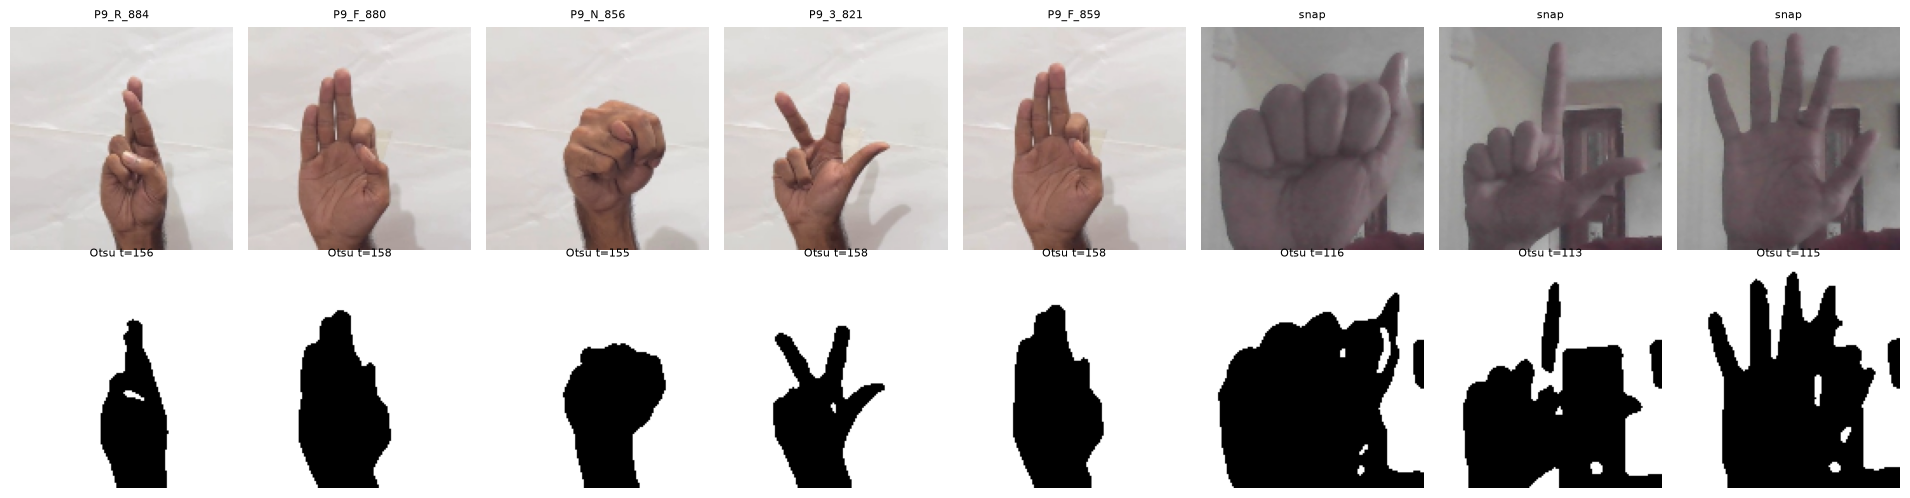

In [5]:
rng = np.random.default_rng(SEED)
sample = list(rng.choice(val_paths, size=5, replace=False))
sample += [f"/mnt/c/sign-lang-webcam/snap_{i}.jpg" for i in range(3)]

fig, axes = plt.subplots(2, len(sample), figsize=(2.4 * len(sample), 5))
for c, p in enumerate(sample):
    bgr = cv2.imread(p)
    bgr = cv2.resize(bgr, (128, 128))
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)
    t, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    axes[0, c].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    axes[0, c].set_title("snap" if "snap_" in p else Path(p).stem, fontsize=8)
    axes[1, c].imshow(mask, cmap="gray")
    axes[1, c].set_title(f"Otsu t={t:.0f}", fontsize=8)
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout()
plt.show()

In [11]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomZoom(0.15),
        layers.RandomRotation(0.04),
        layers.RandomBrightness(0.2, value_range=(0, 1)),
        layers.RandomContrast(0.2),
    ], name="augmentation")

Parameters: 425956


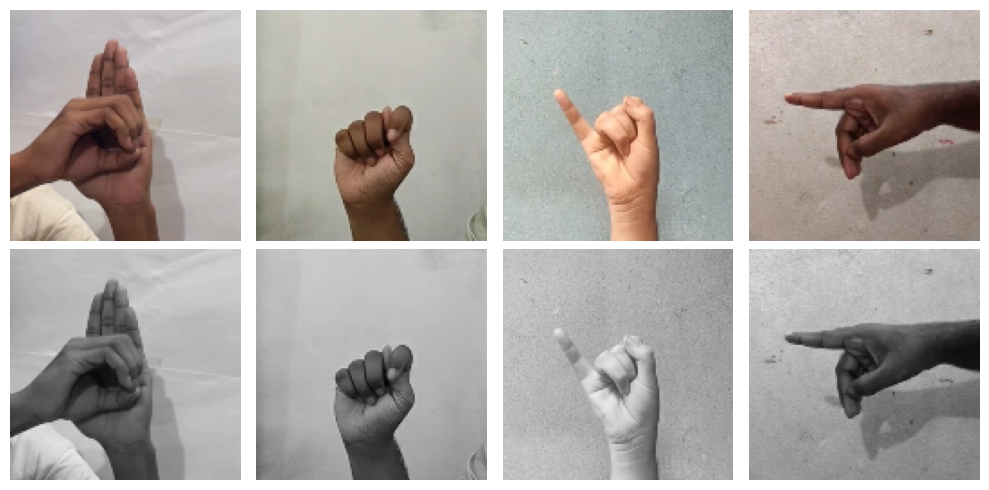

In [12]:
@tf.keras.utils.register_keras_serializable(package="signlang")
class ToGrayscale(layers.Layer):
    """RGB -> grayscale, repeated to 3 channels so the rest of the model is unchanged."""
    def call(self, x):
        return tf.repeat(tf.image.rgb_to_grayscale(x), 3, axis=-1)


def build_cnn(name, augmentation=None, grayscale=False):
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
    x = inputs
    if augmentation is not None:
        x = augmentation(x)
    if grayscale:
        x = ToGrayscale()(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(classes), activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)


# sanity check: same parameter count as before, and the layer really outputs gray
test_model = build_cnn("gray_check", augmentation=make_augmentation(), grayscale=True)
print("Parameters:", test_model.count_params())   # expect 425,956

images, labels = next(iter(train_dataset))
gray = ToGrayscale()(images[:4])
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(4):
    axes[0, i].imshow(images[i].numpy()); axes[0, i].axis("off")
    axes[1, i].imshow(gray[i].numpy());   axes[1, i].axis("off")
plt.tight_layout()
plt.show()

In [17]:
IMAGE_SIZE = (128, 128)   # make sure we're not left in 192 mode

results_gray = []
for seed in [42, 43, 44]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    ds_train = make_dataset(train_paths, train_labels, training=True, seed=seed)
    model = build_cnn("auggray_cnn", augmentation=make_augmentation(), grayscale=True)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    h = model.fit(
        ds_train,
        validation_data=val_dataset,
        epochs=EPOCHS,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True)],
        verbose=2,
    )
    save_run("auggray", seed, model, h.history, notes="regular aug + grayscale layer")
    best = int(np.argmin(h.history["val_loss"]))
    results_gray.append((seed, h.history["val_accuracy"][best]))

for seed, acc in results_gray:
    print(f"auggray seed {seed}: {acc:.3f}")

Epoch 1/30


/home/gouth9/sign-lang-project/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791613344.493600    2029 cuda_dnn.cc:461] Loaded cuDNN version 92700


900/900 - 51s - 57ms/step - accuracy: 0.0610 - loss: 3.3543 - val_accuracy: 0.2214 - val_loss: 2.5272
Epoch 2/30
900/900 - 47s - 52ms/step - accuracy: 0.3385 - loss: 2.0823 - val_accuracy: 0.4722 - val_loss: 1.3116
Epoch 3/30
900/900 - 49s - 55ms/step - accuracy: 0.6389 - loss: 1.0366 - val_accuracy: 0.7186 - val_loss: 0.6494
Epoch 4/30
900/900 - 52s - 58ms/step - accuracy: 0.7963 - loss: 0.5771 - val_accuracy: 0.7042 - val_loss: 0.7781
Epoch 5/30
900/900 - 57s - 63ms/step - accuracy: 0.8720 - loss: 0.3667 - val_accuracy: 0.8128 - val_loss: 0.6028
Epoch 6/30
900/900 - 54s - 60ms/step - accuracy: 0.9048 - loss: 0.2698 - val_accuracy: 0.8061 - val_loss: 0.7170
Epoch 7/30
900/900 - 54s - 60ms/step - accuracy: 0.9262 - loss: 0.2135 - val_accuracy: 0.7961 - val_loss: 0.7308
Epoch 8/30
900/900 - 57s - 64ms/step - accuracy: 0.9442 - loss: 0.1589 - val_accuracy: 0.7400 - val_loss: 1.0687
Epoch 9/30
900/900 - 58s - 64ms/step - accuracy: 0.9534 - loss: 0.1383 - val_accuracy: 0.8506 - val_loss: 0

In [14]:
def make_dataset(paths, labels, training, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds
    

In [16]:
EPOCHS = 30
MODELS_DIR = PROJECT_ROOT / "models"
EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"